# **Hate Speech Classification**

Tujuan project: Membangun model klasifikasi biner menggunakan TF-IDF dan Support Vector Machine yang mampu mengklasifikasikan teks berbahasa Indonesia menjadi kelas hate speech dan non-hate speech.


## **Import Library**

In [ ]:
!pip install nltk
!pip install nlpaug
!pip install Sastrawi
!pip install scikit-learn
!pip install swifter

In [ ]:
import pandas as pd
import numpy as np
import string, re

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split

from collections import Counter
import matplotlib.pyplot as plt

import swifter
import csv

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## **Load Dataset**

In [ ]:
# Membaca dataset hate speech
df = pd.read_csv('data.csv', encoding='latin-1')

In [ ]:
# Menampilkan informasi struktur dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13169 entries, 0 to 13168
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Tweet          13169 non-null  object
 1   HS             13169 non-null  int64 
 2   Abusive        13169 non-null  int64 
 3   HS_Individual  13169 non-null  int64 
 4   HS_Group       13169 non-null  int64 
 5   HS_Religion    13169 non-null  int64 
 6   HS_Race        13169 non-null  int64 
 7   HS_Physical    13169 non-null  int64 
 8   HS_Gender      13169 non-null  int64 
 9   HS_Other       13169 non-null  int64 
 10  HS_Weak        13169 non-null  int64 
 11  HS_Moderate    13169 non-null  int64 
 12  HS_Strong      13169 non-null  int64 
dtypes: int64(12), object(1)
memory usage: 1.3+ MB


In [ ]:
# Menampilkan 5 baris pertama
df.head()

,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatia...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1,1,0,1,1,0,0,0,0,0,1,0


In [ ]:
# Menampilkan 5 baris terakhir
df.tail()

,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
13164,USER jangan asal ngomong ndasmu. congor lu yg ...,1,1,1,0,0,0,1,0,0,1,0,0
13165,USER Kasur mana enak kunyuk',0,1,0,0,0,0,0,0,0,0,0,0
13166,USER Hati hati bisu :( .g\n\nlagi bosan huft \...,0,0,0,0,0,0,0,0,0,0,0,0
13167,USER USER USER USER Bom yang real mudah terdet...,0,0,0,0,0,0,0,0,0,0,0,0
13168,"USER Mana situ ngasih("": itu cuma foto ya kuti...",1,1,1,0,0,0,0,0,1,1,0,0


In [ ]:
# Menampilkan jumlah data untuk kategori Hate Speech
df.HS.value_counts()

,count
HS,
0,7608
1,5561


Label 1 means yes (Hate Speech), 0 mean no (Non-Hate Speech).

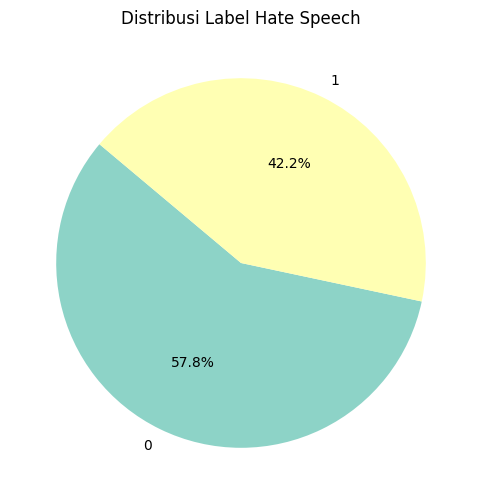

In [ ]:
# Visualisasi distribusi label
plt.figure(figsize=(6, 6))

df['HS'].value_counts().plot.pie(
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Set3.colors,
    labels=df['HS'].value_counts().index
)
plt.title("Distribusi Label Hate Speech")
plt.ylabel('')
plt.show()

In [ ]:
# Mengecek jumlah data yang kosong (missing value)
df.isnull().sum()

,0
Tweet,0
HS,0
Abusive,0
HS_Individual,0
HS_Group,0
HS_Religion,0
HS_Race,0
HS_Physical,0
HS_Gender,0
HS_Other,0


In [ ]:
# Mengecek jumlah data duplikasi
jumlah_duplikat = df.duplicated(subset="Tweet").sum()
print("Jumlah data duplikat:", jumlah_duplikat)

data_duplikat = df[df.duplicated(keep=False)].copy()
data_duplikat

Jumlah data duplikat: 146


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
33,"RT USER: Kelakuan homok jaman now, ngentot aja...",0,1,0,0,0,0,0,0,0,0,0,0
43,#GubernurZamanNow #GusIpulPuti2 #GanjarYasin1 ...,0,0,0,0,0,0,0,0,0,0,0,0
165,Giat Bhabinkamtibmas Brigpol Mbs Sihombing pd ...,0,0,0,0,0,0,0,0,0,0,0,0
182,USER USER USER USER USER USER USER USER USER U...,0,0,0,0,0,0,0,0,0,0,0,0
239,Monyet Turun ke Pemukiman Warga Cibadak Sukabu...,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12793,I added a video to a USER playlist,0,0,0,0,0,0,0,0,0,0,0,0
12952,USER USER USER USER USER USER USER USER USER U...,0,0,0,0,0,0,0,0,0,0,0,0
12953,"SETUJU SAYA,KLAU AHOK DAPAT GELAR SANTRI KEHOR...",1,1,1,0,0,0,0,0,1,1,0,0
12985,USER ahmad dhani yang terhormat paling babi pa...,1,1,1,0,0,0,0,1,0,1,0,0


In [ ]:
# Menghitung jumlah data sebelum dihapus
jumlah_sebelum = len(df)

# Menghapus data duplikat, mempertahankan kemunculan pertama
df = df.drop_duplicates(subset="Tweet", keep="first").copy()

# Menghitung jumlah data setelah dihapus
jumlah_setelah = len(df)

print("Jumlah data sebelum dihapus:", jumlah_sebelum)
print("Jumlah baris duplikat yang dihapus:", jumlah_duplikat)
print("Jumlah data setelah dihapus:", jumlah_setelah)

Jumlah data sebelum dihapus: 13169
Jumlah baris duplikat yang dihapus: 146
Jumlah data setelah dihapus: 13023


In [ ]:
# Mengambil kolom tweet dan HS
df = df[['Tweet', 'HS']]

# Mengecek ulang bentuk dataset
print("Bentuk dataset:", df.shape)

# Menampilkan 5 baris pertama
df.head()

Bentuk dataset: (13023, 2)


,Tweet,HS
0,- disaat semua cowok berusaha melacak perhatia...,1
1,RT USER: USER siapa yang telat ngasih tau elu?...,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1


## **Exploratory Data Analysis (EDA)**

KARAKTERISTIK DATA

In [ ]:
# Mengecek karakteristik data
eda = df.copy()

# Menghitung karakter dan kata
eda["jumlah_karakter"] = eda["Tweet"].fillna("").astype(str).str.len()
eda["jumlah_kata"] = (eda["Tweet"].fillna("").astype(str).str.split().str.len())

eda[["jumlah_karakter", "jumlah_kata"]].describe().round(2)

,jumlah_karakter,jumlah_kata
count,13023.00,13023.00
mean,114.11,17.26
std,69.12,10.24
min,4.00,1.00
25%,59.00,9.00
50%,100.00,15.00
75%,152.00,23.00
max,561.00,52.00


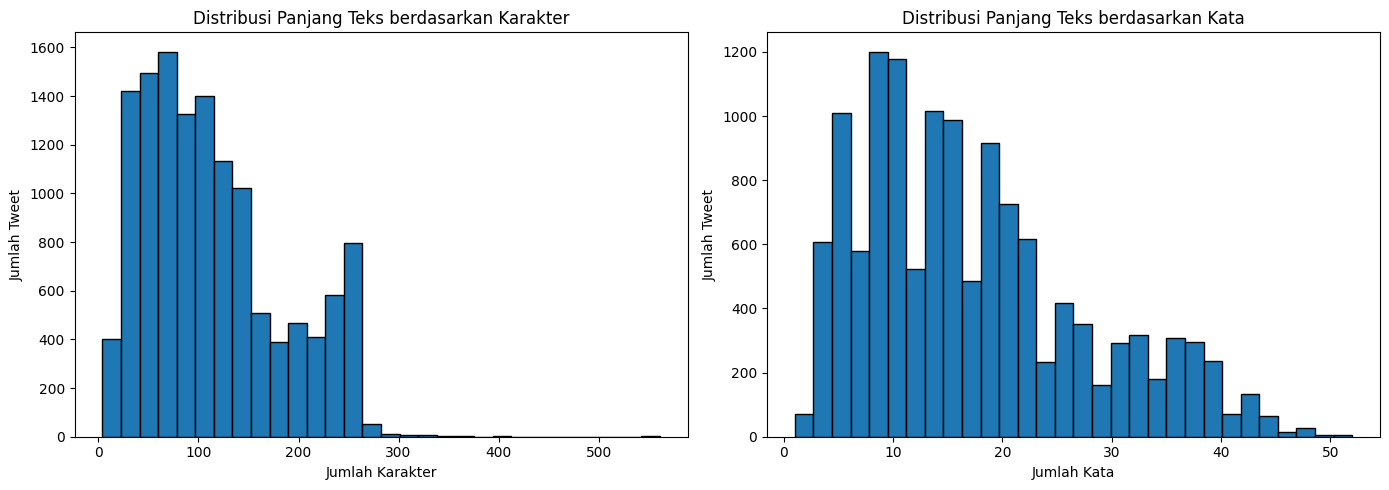

In [ ]:
# Visualisasi distribusi panjang teks
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi jumlah karakter
axes[0].hist(eda["jumlah_karakter"], bins=30, edgecolor="black")
axes[0].set_title("Distribusi Panjang Teks berdasarkan Karakter")
axes[0].set_xlabel("Jumlah Karakter")
axes[0].set_ylabel("Jumlah Tweet")

# Distribusi jumlah kata
axes[1].hist(eda["jumlah_kata"], bins=30, edgecolor="black")
axes[1].set_title("Distribusi Panjang Teks berdasarkan Kata")
axes[1].set_xlabel("Jumlah Kata")
axes[1].set_ylabel("Jumlah Tweet")

plt.tight_layout()
plt.show()

KARAKTER KHUSUS

In [ ]:
# Distribusi karakter
teks = eda["Tweet"].fillna("").astype(str)

karakteristik = pd.DataFrame({
    "Huruf kapital": teks.str.contains(r"[A-Z]{3,}", regex=True),
    "Mengandung URL": teks.str.contains(r"https?://|www\.", case=False, regex=True),
    "Mengandung mention": teks.str.contains(r"@\w+", regex=True),
    "Mengandung hashtag": teks.str.contains(r"#\w+", regex=True),
    "Tanda baca berulang": teks.str.contains(r"[!?.,]{2,}", regex=True),
    "Mengandung angka": teks.str.contains(r"\d", regex=True)
})

distribusi = pd.DataFrame({
    "Karakteristik": karakteristik.columns,
    "Jumlah Tweet": karakteristik.sum().values,
    "Persentase (%)": (karakteristik.mean().values * 100).round(2)
})

distribusi

,Karakteristik,Jumlah Tweet,Persentase (%)
0,Huruf kapital,9419,72.33
1,Mengandung URL,3,0.02
2,Mengandung mention,0,0.00
3,Mengandung hashtag,1292,9.92
4,Tanda baca berulang,3218,24.71
5,Mengandung angka,4356,33.45


In [ ]:
# Statistik panjang teks berdasarkan kelas label
statistik_label = (eda.groupby("HS").agg(
    jumlah_tweet=("Tweet", "count"),
    rata_rata_karakter=("jumlah_karakter", "mean"),
    median_karakter=("jumlah_karakter", "median"),
    rata_rata_kata=("jumlah_kata", "mean"),
    median_kata=("jumlah_kata", "median")
    ).round(2)
)

statistik_label

,jumlah_tweet,rata_rata_karakter,median_karakter,rata_rata_kata,median_kata
HS,,,,,
0,7522,122.85,107.0,18.38,16.0
1,5501,102.16,94.0,15.72,14.0


In [ ]:
# Kata dominan
semua_teks = " ".join(eda["Tweet"].dropna().astype(str).str.lower())

# Mengambil rangkaian huruf sebagai kata sederhana
kata = re.findall(r"\b[a-zA-ZÀ-ÿ]+\b", semua_teks)

frekuensi_kata = Counter(kata)

tabel_kata = pd.DataFrame(frekuensi_kata.most_common(20), columns=["Kata", "Frekuensi"])
tabel_kata

,Kata,Frekuensi
0,user,15493
1,yg,2928
2,dan,2712
3,di,2703
4,yang,1992
5,n,1748
6,itu,1704
7,ini,1563
8,ada,1343
9,ya,954


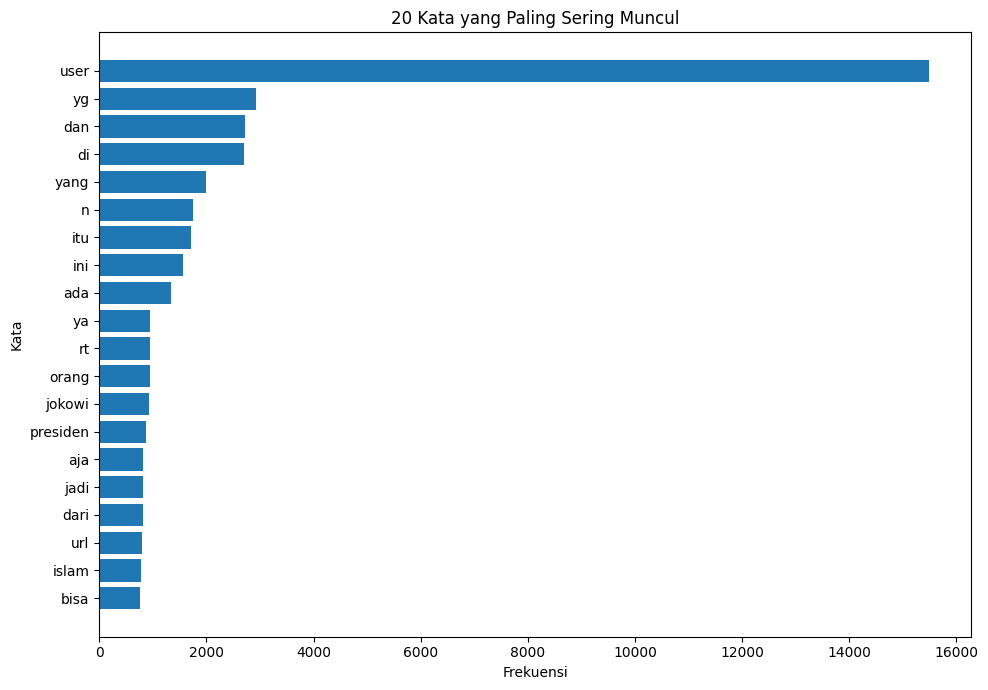

In [ ]:
# Visualisasi 20 kata dominan
tabel_plot = tabel_kata.sort_values("Frekuensi")

plt.figure(figsize=(10, 7))
plt.barh(tabel_plot["Kata"], tabel_plot["Frekuensi"])
plt.title("20 Kata yang Paling Sering Muncul")
plt.xlabel("Frekuensi")
plt.ylabel("Kata")
plt.tight_layout()
plt.show()

## **Preprocessing Data**

CLEANING

In [ ]:
# Cleaning text
def cleaning_text(text):
    text = re.sub(r'#([A-Za-z0-9_]+)', r'\1', text) # Menghapus hastag
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text) # Menghapus URL
    text = re.sub(r'[0-9]+', '', text) # Menghapus angka
    text = text.replace('\n', ' ') # Mengganti baris baru dengan spasi
    text = text.translate(str.maketrans('', '', string.punctuation)) # Menghapus tanda baca
    text = re.sub(r'[^\w\s]', ' ', text, flags=re.UNICODE) # Menghapus karakter selain huruf dan spasi
    text = re.sub(r'\bRT\b', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'\bn\b', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'\s+', ' ', text).strip() # Merapikan spasi
    text = re.sub(r'\bUSER\b', 'USER', text, flags=re.IGNORECASE)

    # Menyisakan hanya satu USER dalam setiap tweet
    words = text.split()
    result = []
    user_kept = False

    for word in words:
        if word.upper() == "USER":
            if not user_kept:
                result.append("USER")
                user_kept = True
        else:
            result.append(word)

    return " ".join(result)

df['cleanpunct'] = df['Tweet'].apply(cleaning_text)
cleanpunct = pd.DataFrame(df['cleanpunct'])
cleanpunct

,cleanpunct
0,disaat semua cowok berusaha melacak perhatian ...
1,USER siapa yang telat ngasih tau eluedan sarap...
2,Kadang aku berfikir kenapa aku tetap percaya p...
3,USER AKU ITU AKUnnKU TAU MATAMU SIPIT TAPI DIL...
4,USER Kaum cebong kapir udah keliatan dongoknya...
...,...
13164,USER jangan asal ngomong ndasmu congor lu yg s...
13165,USER Kasur mana enak kunyuk
13166,USER Hati hati bisu gnnlagi bosan huft xfxfxxaa
13167,USER Bom yang real mudah terdeteksi bom yang t...


CASE FOLDING

In [ ]:
# Case folding
df['lowercase'] = df['cleanpunct'].str.lower()

casefolding = pd.DataFrame(df['lowercase'])
casefolding

,lowercase
0,disaat semua cowok berusaha melacak perhatian ...
1,user siapa yang telat ngasih tau eluedan sarap...
2,kadang aku berfikir kenapa aku tetap percaya p...
3,user aku itu akunnku tau matamu sipit tapi dil...
4,user kaum cebong kapir udah keliatan dongoknya...
...,...
13164,user jangan asal ngomong ndasmu congor lu yg s...
13165,user kasur mana enak kunyuk
13166,user hati hati bisu gnnlagi bosan huft xfxfxxaa
13167,user bom yang real mudah terdeteksi bom yang t...


TOKENIZATION

In [ ]:
# Tokenizing text
def tokenizingText(text):
    tokens = word_tokenize(text)
    return tokens

df['tokens'] = df['lowercase'].apply(tokenizingText)
tokenize = pd.DataFrame(df['tokens'])
tokenize

,tokens
0,"[disaat, semua, cowok, berusaha, melacak, perh..."
1,"[user, siapa, yang, telat, ngasih, tau, elueda..."
2,"[kadang, aku, berfikir, kenapa, aku, tetap, pe..."
3,"[user, aku, itu, akunnku, tau, matamu, sipit, ..."
4,"[user, kaum, cebong, kapir, udah, keliatan, do..."
...,...
13164,"[user, jangan, asal, ngomong, ndasmu, congor, ..."
13165,"[user, kasur, mana, enak, kunyuk]"
13166,"[user, hati, hati, bisu, gnnlagi, bosan, huft,..."
13167,"[user, bom, yang, real, mudah, terdeteksi, bom..."


NORMALIZATION

In [ ]:
# Normalisasi menggunakan kamus
alay_dict = pd.read_csv("new_kamusalay.csv", encoding='latin-1', header=None)
alay_dict.columns = ["original", "replacement"]

# Memeriksa isi dan nama kolom kamus
print("Shape: ", alay_dict.shape)
alay_dict.head(10)

Shape:  (15169, 2)


,original,replacement
0,anakjakartaasikasik,anak jakarta asyik asyik
1,pakcikdahtua,pak cik sudah tua
2,pakcikmudalagi,pak cik muda lagi
3,t3tapjokowi,tetap jokowi
4,3x,tiga kali
5,aamiin,amin
6,aamiinn,amin
7,aamin,amin
8,aammiin,amin
9,abis,habis


In [ ]:
# Normalisasi text
alay_dict_map = dict(zip(alay_dict['original'], alay_dict['replacement']))

def normalizationText(tokens):
    if isinstance(tokens, str):
        tokens = tokens.split()

    normalized_tokens = []

    for word in tokens:
        replacement = alay_dict_map.get(word, word)

        normalized_tokens.extend(replacement.split())

    return normalized_tokens

df["normalization"] = df["tokens"].apply(normalizationText)
normalisasi = pd.DataFrame(df['normalization'])
normalisasi

,normalization
0,"[di, saat, semua, cowok, berusaha, melacak, pe..."
1,"[pengguna, siapa, yang, telat, memberi, tau, e..."
2,"[kadang, aku, berpikir, kenapa, aku, tetap, pe..."
3,"[pengguna, aku, itu, akunku, tau, matamu, sipi..."
4,"[pengguna, kaum, cebong, kafir, sudah, kelihat..."
...,...
13164,"[pengguna, jangan, asal, berbicara, ndasmu, co..."
13165,"[pengguna, kasur, mana, enak, kunyuk]"
13166,"[pengguna, hati, hati, bisu, gnnlagi, bosan, d..."
13167,"[pengguna, bom, yang, real, mudah, terdeteksi,..."


STOPWORD REMOVAL

In [ ]:
# Stopword bahasa Indonesia
factory = StopWordRemoverFactory()
stopwords = set(factory.get_stop_words())

def stopwordRemoval(tokens):
    return [word for word in tokens if word not in stopwords]

df["stopword"] = df["normalization"].apply(stopwordRemoval)
stopword = pd.DataFrame(df['stopword'])
stopword

,stopword
0,"[semua, cowok, berusaha, melacak, perhatian, g..."
1,"[pengguna, siapa, telat, memberi, tau, elu, ed..."
2,"[kadang, aku, berpikir, aku, tetap, percaya, t..."
3,"[pengguna, aku, akunku, tau, matamu, sipit, di..."
4,"[pengguna, kaum, cebong, kafir, kelihatan, don..."
...,...
13164,"[pengguna, jangan, asal, berbicara, ndasmu, co..."
13165,"[pengguna, kasur, mana, enak, kunyuk]"
13166,"[pengguna, hati, hati, bisu, gnnlagi, bosan, d..."
13167,"[pengguna, bom, real, mudah, terdeteksi, bom, ..."


STEMMING

In [ ]:
# Stemming Text
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stemmingText(tokens):
   stems = [stemmer.stem(word) for word in tokens]
   return ' '.join(stems)

df["stemming"] = df["stopword"].swifter.apply(stemmingText)
stemming = pd.DataFrame(df['stemming'])
stemming

Pandas Apply:   0%|          | 0/13023 [00:00<?, ?it/s]

,stemming
0,semua cowok usaha lacak perhati gue kamu lanta...
1,guna siapa telat beri tau elu edan sarap gue g...
2,kadang aku pikir aku tetap percaya tuhan padah...
3,guna aku akun tau mata sipit lihat mana aku
4,guna kaum cebong kafir lihat dongok awal tamba...
...,...
13164,guna jangan asal bicara ndasmu congor kamu kat...
13165,guna kasur mana enak kunyuk
13166,guna hati hati bisu gnnlagi bosan duh xfxfxxaa
13167,guna bom real mudah deteksi bom kubur suatu le...


In [ ]:
df.to_csv('data_preprocessing.csv', index=False)
print("File berhasil disimpan")

File berhasil disimpan


In [ ]:
df.head()

,Tweet,HS,cleanpunct,lowercase,tokens,normalization,stopword,stemming
0,- disaat semua cowok berusaha melacak perhatia...,1,disaat semua cowok berusaha melacak perhatian ...,disaat semua cowok berusaha melacak perhatian ...,"[disaat, semua, cowok, berusaha, melacak, perh...","[di, saat, semua, cowok, berusaha, melacak, pe...","[semua, cowok, berusaha, melacak, perhatian, g...",semua cowok usaha lacak perhati gue kamu lanta...
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,USER siapa yang telat ngasih tau eluedan sarap...,user siapa yang telat ngasih tau eluedan sarap...,"[user, siapa, yang, telat, ngasih, tau, elueda...","[pengguna, siapa, yang, telat, memberi, tau, e...","[pengguna, siapa, telat, memberi, tau, elu, ed...",guna siapa telat beri tau elu edan sarap gue g...
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,Kadang aku berfikir kenapa aku tetap percaya p...,kadang aku berfikir kenapa aku tetap percaya p...,"[kadang, aku, berfikir, kenapa, aku, tetap, pe...","[kadang, aku, berpikir, kenapa, aku, tetap, pe...","[kadang, aku, berpikir, aku, tetap, percaya, t...",kadang aku pikir aku tetap percaya tuhan padah...
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0,USER AKU ITU AKUnnKU TAU MATAMU SIPIT TAPI DIL...,user aku itu akunnku tau matamu sipit tapi dil...,"[user, aku, itu, akunnku, tau, matamu, sipit, ...","[pengguna, aku, itu, akunku, tau, matamu, sipi...","[pengguna, aku, akunku, tau, matamu, sipit, di...",guna aku akun tau mata sipit lihat mana aku
4,USER USER Kaum cebong kapir udah keliatan dong...,1,USER Kaum cebong kapir udah keliatan dongoknya...,user kaum cebong kapir udah keliatan dongoknya...,"[user, kaum, cebong, kapir, udah, keliatan, do...","[pengguna, kaum, cebong, kafir, sudah, kelihat...","[pengguna, kaum, cebong, kafir, kelihatan, don...",guna kaum cebong kafir lihat dongok awal tamba...


## **Splitting Data**

In [ ]:
# Baca dataset
df = pd.read_csv('data_preprocessing.csv')

print("Jumlah data hasil preprocessing:", len(df))

Jumlah data hasil preprocessing: 13023


In [ ]:
# Memeriksa teks duplikat dengan label yang berbeda untuk mencegah data leakge
label_per_teks = df.groupby('stemming')['HS'].nunique()
teks_bermasalah = label_per_teks[label_per_teks > 1].index

print("Jumlah teks dengan label yang berbeda:", len(teks_bermasalah))

if len(teks_bermasalah) > 0:
    print("Contoh teks dengan label berbeda:")
    display(df[df['stemming'].isin(teks_bermasalah)].sort_values('stemming').head(50))

Jumlah teks dengan label yang berbeda: 5
Contoh teks dengan label berbeda:


,Tweet,HS,cleanpunct,lowercase,tokens,normalization,stopword,stemming
182,USER USER USER USER USER USER USER USER USER U...,0,USER,user,['user'],['pengguna'],['pengguna'],guna
6975,USER Haruss,0,USER Haruss,user haruss,"['user', 'haruss']","['pengguna', 'harus']",['pengguna'],guna
1280,USER USER USER USER USER USER USER USER USER U...,0,USER,user,['user'],['pengguna'],['pengguna'],guna
488,USER USER USER USER USER USER USER USER USER U...,0,USER,user,['user'],['pengguna'],['pengguna'],guna
3820,USER USER USER USER USER USER USER USER USER U...,0,USER,user,['user'],['pengguna'],['pengguna'],guna
317,USER USER USER USER USER USER USER USER USER U...,0,USER,user,['user'],['pengguna'],['pengguna'],guna
288,USER USER USER USER USER USER USER USER USER U...,1,USER,user,['user'],['pengguna'],['pengguna'],guna
376,USER USER USER USER USER USER USER USER USER U...,0,USER,user,['user'],['pengguna'],['pengguna'],guna
2521,USER USER anjir ga gitu jg bloon',1,USER anjir ga gitu jg bloon,user anjir ga gitu jg bloon,"['user', 'anjir', 'ga', 'gitu', 'jg', 'bloon']","['pengguna', 'anjir', 'tidak', 'begitu', 'juga...","['pengguna', 'anjir']",guna anjir
5913,USER Kaga anjir',0,USER Kaga anjir,user kaga anjir,"['user', 'kaga', 'anjir']","['pengguna', 'tidak', 'anjir']","['pengguna', 'anjir']",guna anjir


In [ ]:
# Hitung jumlah baris yang akan dihapus
mask_konflik = df['stemming'].isin(teks_bermasalah)

print("Jumlah kelompok teks bermasalah:", len(teks_bermasalah))
print("Jumlah baris yang akan dihapus:", mask_konflik.sum())

# Hapus seluruh baris dari kelompok bermasalah dikarenakan tweet tersebut tidak dapat dipastikan label yang benar
df = df.loc[~mask_konflik].copy()
print("Jumlah data setelah dihapus:", len(df))

# Memastikan tidak ada konflik label tersisa
konflik_sisa = (df.groupby('stemming')['HS'].nunique().gt(1).sum())
print("Jumlah konflik label tersisa:", konflik_sisa)

Jumlah kelompok teks bermasalah: 5
Jumlah baris yang akan dihapus: 17
Jumlah data setelah dihapus: 13006
Jumlah konflik label tersisa: 0


In [ ]:
# Menghapus duplikasi berdasarkan teks stemming
jumlah_duplikat = df.duplicated(subset=['stemming'], keep='first').sum()

df = df.drop_duplicates(subset=['stemming'], keep='first').copy()

print("Jumlah duplikasi yang dihapus:", jumlah_duplikat)
print("Jumlah data final:", len(df))

# Distribusi label HS
print("Distribusi label HS:")
distribusi_hs = pd.DataFrame({
    'Jumlah Data': df['HS'].value_counts().sort_index(),
    'Persentase (%)': (df['HS'].value_counts(normalize=True).sort_index() * 100).round(2)
})

distribusi_hs

Jumlah duplikasi yang dihapus: 134
Jumlah data final: 12872
Distribusi label HS:


,Jumlah Data,Persentase (%)
HS,,
0,7440,57.8
1,5432,42.2


In [ ]:
# Fitur dan target
X = df['stemming']
y = df['HS']

# Split training 80% dan validation + testing 20%
X_train, X_valtest, y_train, y_valtest = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split validation 10% dan testing 10% dari total data
X_val, X_test, y_val, y_test = train_test_split(
    X_valtest,
    y_valtest,
    test_size=0.50,
    random_state=42,
    stratify=y_valtest
)

# Simpan hasil splitting
train_df = pd.DataFrame({
    'stemming': X_train,
    'HS': y_train
})

val_df = pd.DataFrame({
    'stemming': X_val,
    'HS': y_val
})

test_df = pd.DataFrame({
    'stemming': X_test,
    'HS': y_test
})

# Jumlah data
print("Jumlah data setiap split:")
print(f"Training   : {len(train_df)} ({len(train_df)/len(df)*100:.2f}%)")
print(f"Validation : {len(val_df)} ({len(val_df)/len(df)*100:.2f}%)")
print(f"Testing    : {len(test_df)} ({len(test_df)/len(df)*100:.2f}%)")
print(f"Total      : {len(train_df) + len(val_df) + len(test_df)}")

# Simpan ke CSV
train_df.rename(columns={'stemming': 'Tweet'}).to_csv('data_train.csv', index=False)
val_df.rename(columns={'stemming': 'Tweet'}).to_csv('data_validation.csv', index=False)
test_df.rename(columns={'stemming': 'Tweet'}).to_csv('data_test.csv', index=False)

print("\nFile splitting berhasil disimpan")

Jumlah data setiap split:
Training   : 10297 (80.00%)
Validation : 1287 (10.00%)
Testing    : 1288 (10.01%)
Total      : 12872

File splitting berhasil disimpan


In [ ]:
# Cek duplikasi lintas split
train_text = set(train_df['stemming'])
val_text = set(val_df['stemming'])
test_text = set(test_df['stemming'])

print("Cek duplikasi lintas split:")
print("Train - Validation:", len(train_text & val_text))
print("Train - Test      :", len(train_text & test_text))
print("Validation - Test :", len(val_text & test_text))

Cek duplikasi lintas split:
Train - Validation: 0
Train - Test      : 0
Validation - Test : 0


In [ ]:
# Cek distribusi kelas HS setiap split
hasil_distribusi = []

for nama, subset in [
    ('Training', train_df),
    ('Validation', val_df),
    ('Testing', test_df)
]:
    jumlah = subset['HS'].value_counts().sort_index()
    persentase = (subset['HS'].value_counts(normalize=True).sort_index() * 100)

    for label in [0, 1]:
        hasil_distribusi.append({
            'Subset': nama,
            'Label HS': {
                0: 'Non-Hate Speech',
                1: 'Hate Speech'
            }[label],
            'Jumlah Data': jumlah.get(label, 0),
            'Persentase (%)': round(persentase.get(label, 0), 2)
        })

distribusi_hs = pd.DataFrame(hasil_distribusi)
distribusi_hs

,Subset,Label HS,Jumlah Data,Persentase (%)
0,Training,Non-Hate Speech,5952,57.80
1,Training,Hate Speech,4345,42.20
2,Validation,Non-Hate Speech,744,57.81
3,Validation,Hate Speech,543,42.19
4,Testing,Non-Hate Speech,744,57.76
5,Testing,Hate Speech,544,42.24
